In [1]:
from matplotlib import pyplot as plt
import scipy
import numpy as np
from scipy import sparse
import sys
sys.path.insert(0, '..')   # goes from paper_plots/fig_1_compQITE -> repo root
from modules import Hamiltonian as ham
from modules import PauliStrings
from modules import Evolution as evol
from matplotlib.lines import Line2D

In [2]:
color1="#0041FC"
color2="#FC9904"
color3="#7D7548"

In [3]:
def fidelity_pure(psi,phi):
    '''
    input values should be column vectors
    '''
    F=np.abs(psi.conj().T@phi)**2
    return F

In [4]:
ordQITE = np.load("tfim_ord/qite_default/trajectory.npz", allow_pickle=True)
disQITE = np.load("tfim_disord/qite_default/trajectory.npz", allow_pickle=True)

ordSpQ = np.load("tfim_ord/sparse_qite_lambda_0p001/trajectory.npz", allow_pickle=True)
disSpQ = np.load("tfim_disord/sparse_qite_lambda_0p001/trajectory.npz", allow_pickle=True)

ordSpQ_freeze = np.load("tfim_ord/jaccard_lasso_lambda_0p001_Jcum0p9_P3_stol1em14/trajectory.npz", allow_pickle=True)
disSpQ_freeze = np.load("tfim_disord/jaccard_lasso_lambda_0p001_Jcum0p9_P3_stol1em14/trajectory.npz", allow_pickle=True)

In [5]:
N = 100
Ns=np.arange(0,N)
NQ_ord=np.count_nonzero(ordQITE["a"][1])
NQ_dis=np.count_nonzero(disQITE["a"][1])

frac_ord = np.zeros(N)
frac_dis = np.zeros(N)

frac_ord_freeze = np.zeros(N)
frac_dis_freeze = np.zeros(N)
tol = 0
for i in range(N):
    frac_ord[i] = np.count_nonzero(np.abs(ordSpQ["a"][i])>tol) / NQ_ord
    frac_dis[i] = np.count_nonzero(np.abs(disSpQ["a"][i])>tol) / NQ_dis
    frac_ord_freeze[i] = np.count_nonzero(np.abs(ordSpQ_freeze["a"][i])>tol) / NQ_ord
    frac_dis_freeze[i] = np.count_nonzero(np.abs(disSpQ_freeze["a"][i])>tol) / NQ_dis

In [6]:
print(NQ_ord, NQ_dis)
print(frac_ord[-1])

16128 960
0.034660218253968256


In [7]:
def cumulative_support_jaccard(coefficients):
    """Track overlap between previously seen nonzero terms and cumulative support."""
    coefficients = np.asarray(coefficients)
    jaccard = np.ones(coefficients.shape[0], dtype=float)
    new_terms = np.zeros(coefficients.shape[0], dtype=int)
    cumulative_terms = np.zeros(coefficients.shape[0], dtype=int)
    cumulative_support = set()

    for step, coefficient_step in enumerate(coefficients):
        active_support = set(np.flatnonzero(np.asarray(coefficient_step).reshape(-1) != 0))
        previous_size = len(cumulative_support)
        new_terms[step] = len(active_support - cumulative_support)
        cumulative_support.update(active_support)
        cumulative_terms[step] = len(cumulative_support)
        jaccard[step] = previous_size / len(cumulative_support) if cumulative_support else 1.0

    return jaccard, new_terms, cumulative_terms


jaccard_ord_freeze, new_terms_ord_freeze, cumulative_terms_ord_freeze = cumulative_support_jaccard(ordSpQ_freeze["a"])
jaccard_dis_freeze, new_terms_dis_freeze, cumulative_terms_dis_freeze = cumulative_support_jaccard(disSpQ_freeze["a"])


In [8]:
psiordQITE = sparse.load_npz("tfim_ord/qite_default/states.npz").toarray()
psidisQITE = sparse.load_npz("tfim_disord/qite_default/states.npz").toarray()

psiordSpQ = sparse.load_npz("tfim_ord/sparse_qite_lambda_0p001/states.npz").toarray()
psidisSpQ = sparse.load_npz("tfim_disord/sparse_qite_lambda_0p001/states.npz").toarray()

psiordSpQ_freeze = sparse.load_npz("tfim_ord/jaccard_lasso_lambda_0p001_Jcum0p9_P3_stol1em14/states.npz").toarray()
psidisSpQ_freeze = sparse.load_npz("tfim_disord/jaccard_lasso_lambda_0p001_Jcum0p9_P3_stol1em14/states.npz").toarray()

In [9]:
H_ord, Htrot = ham.TFIM(1,0.5,8,2,False)
E_ord,V_ord = np.linalg.eigh(H_ord)
GS_ord = V_ord[:,0]
print(E_ord[0])
H_dis, Htrot = ham.TFIM(0.5,1,8,2,False)
E_dis,V_dis = np.linalg.eigh(H_dis)
GS_dis = V_dis[:,0]
print(E_dis[0])


-8.509082235140282
-8.509082235140271


In [10]:
F_Q_ord = np.zeros(N)
F_Sp_ord = np.zeros(N)
F_Q_dis = np.zeros(N)
F_Sp_dis = np.zeros(N)
F_Spfreeze_ord = np.zeros(N) 
F_Spfreeze_dis = np.zeros(N) 


for i in range(N):
    F_Q_ord[i]  = fidelity_pure(GS_ord,psiordQITE[:,i])
    F_Sp_ord[i] = fidelity_pure(GS_ord,psiordSpQ[:,i])
    F_Q_dis[i]  = fidelity_pure(GS_dis,psidisQITE[:,i])
    F_Sp_dis[i] = fidelity_pure(GS_dis,psidisSpQ[:,i])
    F_Spfreeze_ord[i] = fidelity_pure(GS_ord,psiordSpQ_freeze[:,i])
    F_Spfreeze_dis[i] = fidelity_pure(GS_dis,psidisSpQ_freeze[:,i])

dt=0.05
im_tau = np.arange(0,N)*dt

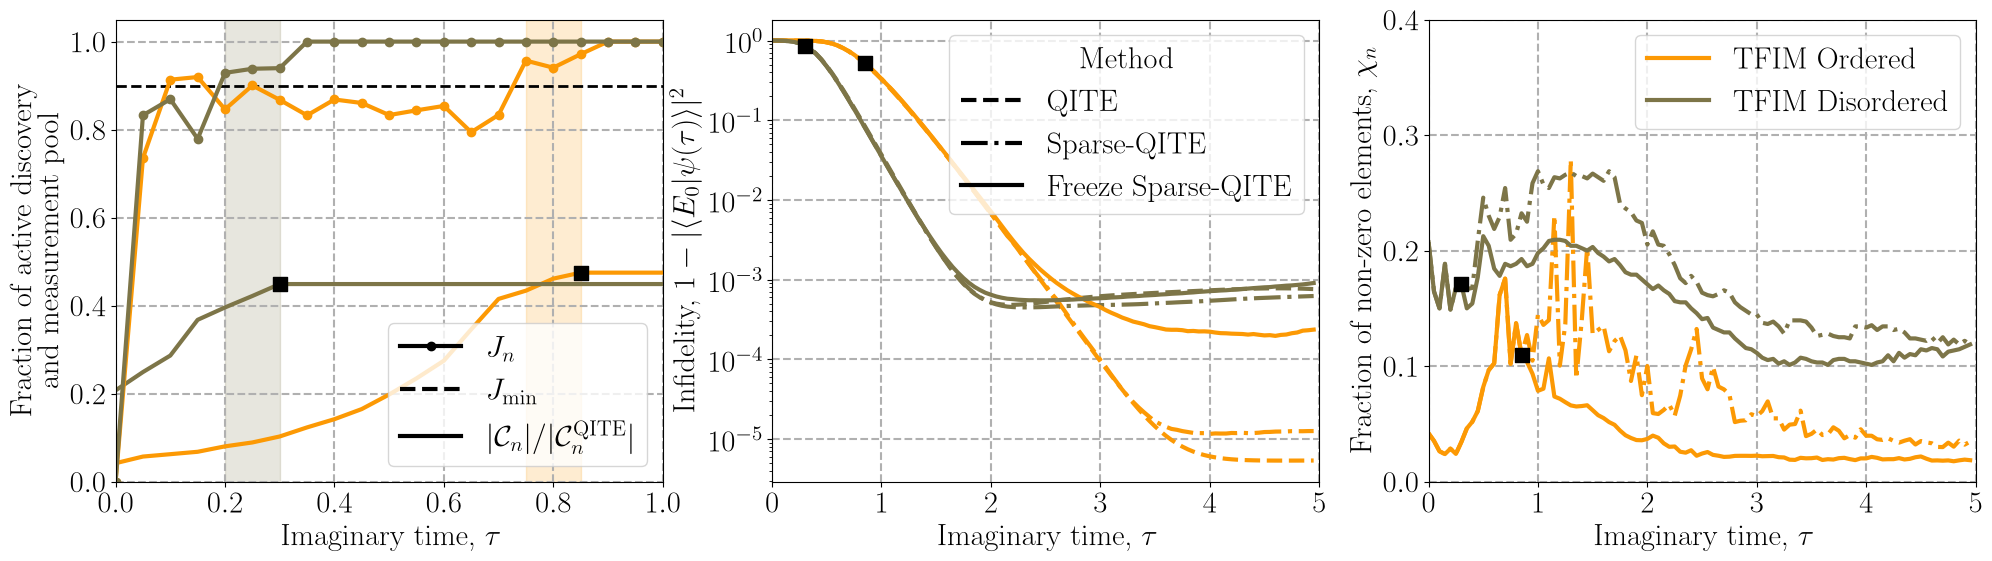

In [11]:
plt.figure(figsize=(24, 6))
plt.rcParams.update({
    "text.usetex": True,
})
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 22}

plt.rc('font', **font)

plt.subplot(1,3,1)
plt.plot(im_tau,cumulative_terms_ord_freeze/NQ_ord, '-', label="Ordered", color=color2, linewidth = 3)
plt.plot(im_tau,cumulative_terms_dis_freeze/NQ_dis, '-', label="Disordered", color=color3, linewidth = 3)
plt.hlines(y=0.9, xmin=0, xmax=len(jaccard_ord_freeze), color="black", linestyle="--", linewidth=2)
plt.plot(im_tau,jaccard_ord_freeze, '-o', label="Ordered Jaccard", color=color2, linewidth = 3)
plt.plot(im_tau,jaccard_dis_freeze, '-o', label="Disordered Jaccard", color=color3, linewidth =3)
plt.xlabel("Imaginary time, $\\tau$")
plt.ylabel("Fraction of active discovery \n and measurement pool")

legend_items = [
    Line2D([0], [0],  lw=3, linestyle="-",marker='o',color='black',  label="$J_n$"),
    Line2D([0], [0],  lw=3, linestyle="--",color='black',  label="$J_\\mathrm{min}$"),
    Line2D([0], [0],  lw=3, linestyle="-",color='black', label="$|\\mathcal{C}_n|/|\\mathcal{C}_n^\\mathrm{QITE}|$"),
]
plt.legend(handles=legend_items)

for values, color in (
    (jaccard_ord_freeze, color2),
    (jaccard_dis_freeze, color3),
):
    above = np.asarray(values) > 0.9
    run_starts = np.flatnonzero(
        np.convolve(above, np.ones(3, dtype=int), mode="valid") == 3
    )

    if run_starts.size:
        start = run_starts[0]
        plt.axvspan((start)*dt, (start + 2)*dt, color=color, alpha=0.18)
        plt.scatter((start+2)*dt,cumulative_terms_ord_freeze[start+2]/NQ_ord if color==color2 else cumulative_terms_dis_freeze[start+2]/NQ_dis, color='black', marker='s', s=100, zorder=5)
        #plt.axvline(
        #    x=(start + 2)*dt,
        #    color=color,
        #    linestyle="-",
        #    linewidth=3,
        #)
        if color == color2:
            ind_ord = start + 2
            t_ord =ind_ord*dt
        else:                  
            ind_dis = start + 2
            t_dis = ind_dis*dt


plt.xlim(0,1)
plt.ylim(0,1.05)
plt.grid(linestyle = '--', linewidth = 1.5)

plt.subplot(1,3,2)
plt.semilogy(im_tau,1-F_Q_ord,'--',color=color2,linewidth=3,label='Ordered $\\lambda = 0.002$')
plt.semilogy(im_tau,1-F_Q_dis,'--',color=color3,linewidth=3,label='Disordered $\\lambda = 0.0015$')
plt.semilogy(im_tau,1-F_Sp_ord,'-.',color=color2,linewidth=3,label='Ordered $\\lambda = 0.002$')
plt.semilogy(im_tau,1-F_Sp_dis,'-.',color=color3,linewidth=3,label='Disordered $\\lambda = 0.0015$')
plt.semilogy(im_tau,1-F_Spfreeze_ord,'-',color=color2,linewidth=3,label='Ordered $\\lambda = 0.002$')
plt.semilogy(im_tau,1-F_Spfreeze_dis,'-',color=color3,linewidth=3,label='Disordered $\\lambda = 0.0015$')
plt.scatter(t_ord,1-F_Spfreeze_ord[ind_ord], color='black', marker='s', s=100, zorder=5)
plt.scatter(t_dis,1-F_Spfreeze_dis[ind_dis], color='black', marker='s', s=100, zorder=5)

legend_items = [
    Line2D([0], [0],  lw=3, linestyle="--",color='black',  label="QITE"),
    Line2D([0], [0],  lw=3, linestyle="-.",color='black', label="Sparse-QITE"),
    Line2D([0], [0],  lw=3, linestyle="-",color='black', label="Freeze Sparse-QITE"),
]

plt.legend(handles=legend_items, title="Method")

plt.xlim(0,5)
plt.xlabel("Imaginary time, $\\tau$")
plt.ylabel("Infidelity, $1-|\\langle E_0 | \\psi(\\tau) \\rangle|^2$")
plt.grid(linestyle = '--', linewidth = 1.5)

plt.subplot(1,3,3)
plt.plot(im_tau,frac_ord,'-.',color=color2,linewidth=3,label='TFIM Ordered $\\lambda = 0.002$')
plt.plot(im_tau,frac_dis,'-.',color=color3,linewidth=3,label='TFIM Disordered $\\lambda = 0.0015$')
plt.plot(im_tau,frac_ord_freeze,'-',color=color2,linewidth=3,label='TFIM Ordered $\\lambda = 0.002$')
plt.plot(im_tau,frac_dis_freeze,'-',color=color3,linewidth=3,label='TFIM Disordered $\\lambda = 0.0015$')
plt.scatter(t_ord,frac_ord_freeze[ind_ord], color='black', marker='s', s=100, zorder=5)
plt.scatter(t_dis,frac_dis_freeze[ind_dis], color='black', marker='s', s=100, zorder=5)

plt.xlabel("Imaginary time, $\\tau$")
plt.ylabel("Fraction of non-zero elements, $\\chi_n$")
plt.ylim(0,0.4)
plt.xlim(0,5)
legend_items = [
    Line2D([0], [0],  lw=3, linestyle="-",color=color2,  label="TFIM Ordered"),
    Line2D([0], [0],  lw=3, linestyle="-",color=color3, label="TFIM Disordered"),
]
plt.legend(handles=legend_items)
plt.grid(linestyle = '--', linewidth = 1.5)

plt.savefig("Freeze_SpQITE.pdf", bbox_inches='tight', dpi=300)